Task 1 compares model performance for the task of predicting hospitalization at ED triage.

# Set-Up

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [21]:
import numpy as np
import polars as pl
import tqdm
import importlib
import logging
import mlflow
from mlflow import MlflowClient
from pathlib import Path
from pprint import pprint
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

from models.config import Config
from models.data_prep import DataPartition
import models.metrics as metrics
from models import plots

# quiet mlflow warnings
logging.getLogger("mlflow").setLevel(logging.ERROR)

# set path to local data
path = Path().resolve().parent / "data"

## Environment Parameters

In [3]:
TARGET = "outcome_hospitalization"

### Helper Functions

In [24]:
## mlflow helper functions for model management ##

def get_model_uri_from_runs(experiment_id: str, run_name: str, artifact_path: str = "model") -> str:
    """Return the `runs:/` URI of the most recent run with the given name."""
    runs = mlflow.search_runs(
        experiment_ids=[experiment_id],
        filter_string=f"tags.mlflow.runName = '{run_name}'",
        order_by=["attributes.start_time DESC"],
        max_results=1,
    )
    if runs.empty:
        raise RuntimeError(f"No MLflow run found with name {run_name!r}.")
    return f"runs:/{runs.iloc[0]['run_id']}/{artifact_path}"


def _flavor_module(flavor: str):
    """Return the `mlflow.<flavor>` module (e.g. `mlflow.xgboost`)."""
    return importlib.import_module(f"mlflow.{flavor}")


def log_model(model: object, artifact_path: str = "model", flavor: str | None = None, **kwargs) -> str:
    """Log a model to the active MLflow run and return its `runs:/` URI.
    Inherits mlflow model flavor from `flavor`, inferring from the model's top-level package if omitted.
    Extra `kwargs` go to the flavor's `log_model` (e.g. `skops_trusted_types` for sklearn).
    """
    active_run = mlflow.active_run()
    if active_run is None:
        raise RuntimeError("Start an MLflow run before logging a model.")

    flavor = flavor or type(model).__module__.split(".")[0]
    try:
        flavor_module = _flavor_module(flavor)
    except ImportError as e:
        raise ValueError(f"No MLflow flavor {flavor!r}; pass `flavor=` explicitly.") from e
    flavor_module.log_model(model, artifact_path=artifact_path, **kwargs)
    return f"runs:/{active_run.info.run_id}/{artifact_path}"


def register_model_version(model_uri: str, model_name: str, alias: str | None = None):
    """Register a model URI as a new version of `model_name`."""
    version = mlflow.register_model(model_uri, model_name)
    if alias is not None:
        # alias APIs live on the client, not the top-level `mlflow` module
        MlflowClient().set_registered_model_alias(model_name, alias, version.version)
    return version


def load_registered_model(model_name: str, alias: str | None = None):
    """Load a registered scikit-learn model by name."""
    client = MlflowClient()
    try:
        if alias is not None:
            version = client.get_model_version_by_alias(model_name, alias)
        else:
            versions = client.search_model_versions(f"name = '{model_name}'")
            if not versions:
                raise ValueError(f"No versions found for registered model {model_name!r}.")
            version = max(versions, key=lambda v: int(v.version))
    except mlflow.exceptions.MlflowException as e:
        raise ValueError(f"Could not resolve {model_name!r} (alias={alias!r}): {e}") from e

    print(f"Loading {model_name!r} version {version.version}" + (f" (alias {alias!r})" if alias else ""))
    uri = f"models:/{model_name}/{version.version}"
    flavors = set(mlflow.models.get_model_info(uri).flavors) - {"python_function"}
    if not flavors:
        return mlflow.pyfunc.load_model(uri)
    return _flavor_module(sorted(flavors)[0]).load_model(uri)

# Define Data

In [5]:
train_df = pl.read_parquet(path / "outputs/train.parquet")
test_df = pl.read_parquet(path / "outputs/test.parquet")
print(f"train_df shape: {train_df.shape}")
print(f"test_df shape:  {test_df.shape}")

train_df shape: (353150, 124)
test_df shape:  (88287, 124)


In [6]:
# binarize `gender` using LabelEncoder -- matches original approach
le = LabelEncoder()

train_df = train_df.with_columns(pl.Series("gender", le.fit_transform(train_df["gender"].to_numpy())))
test_df = test_df.with_columns(pl.Series("gender", le.transform(test_df["gender"].to_numpy())))

In [7]:
# use DataPartition objects for convenience -- use default features from default config
train = DataPartition(train_df, target=TARGET, config=Config())
test = DataPartition(test_df, target=TARGET, config=Config())

In [8]:
# Eval target class ratio
train_rate = train.y.sum().item() / train.y.shape[0]
test_rate = test.y.sum().item() / test.y.shape[0]
print(f"Training Target Class Distribution: Rate: {train_rate:,.4f}  |  Ratio: {train_rate / (1 - train_rate):,.4f}")
print(f"Testing Target Class Distribution:  Rate: {test_rate:,.4f}  |  Ratio: {test_rate / (1 - test_rate):,.4f}")

Training Target Class Distribution: Rate: 0.4734  |  Ratio: 0.8988
Testing Target Class Distribution:  Rate: 0.4736  |  Ratio: 0.8996


# Model Benchmarks

In [9]:
# create mlflow experiment for model telemetry and logging
mlflow.set_experiment("mimic4ed-benchmarks")
experiment = mlflow.get_experiment_by_name("mimic4ed-benchmarks")

## Logistic Regression

In [10]:
from time import perf_counter
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42, max_iter=100)

# log with mlflow
with mlflow.start_run(run_name="logistic-regression"):
    mlflow.log_params(lr.get_params())

    start_time = perf_counter()
    lr.fit(train.X, train.y)
    fit_time_seconds = perf_counter() - start_time
    mlflow.log_metric("fit_time_seconds", fit_time_seconds)

    y_true = test.y
    y_pred = lr.predict(test.X)
    y_prob = lr.predict_proba(test.X)[:, 1]

    lr_metrics = metrics.BasicMetrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        cm=confusion_matrix(y_true, y_pred, labels=lr.classes_).ravel(),
    )

    mlflow.log_metrics(lr_metrics.dict)
    model_uri = log_model(lr, artifact_path="model", flavor="sklearn")

print(f"Training Time: {fit_time_seconds:,.2f}")
pprint(lr_metrics.dict)

c:\Users\benak\repos\mimic4ed-task\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Time: 6.25
{'accuracy': 0.734751435658704,
 'average_precision': 0.7735574351359575,
 'f1': 0.7095621976931663,
 'fn': 13205.0,
 'fp': 10213.0,
 'precision': 0.7369071846260852,
 'recall': 0.6841740211905958,
 'roc_auc': 0.8078960900818342,
 'specificity': 0.7802521731646441,
 'tn': 36263.0,
 'tp': 28606.0}


In [13]:
# register the model
lr_version = register_model_version(model_uri, model_name="logistic-regression", alias="basic")

Registered model 'logistic-regression' already exists. Creating a new version of this model...
Created version '6' of model 'logistic-regression'.


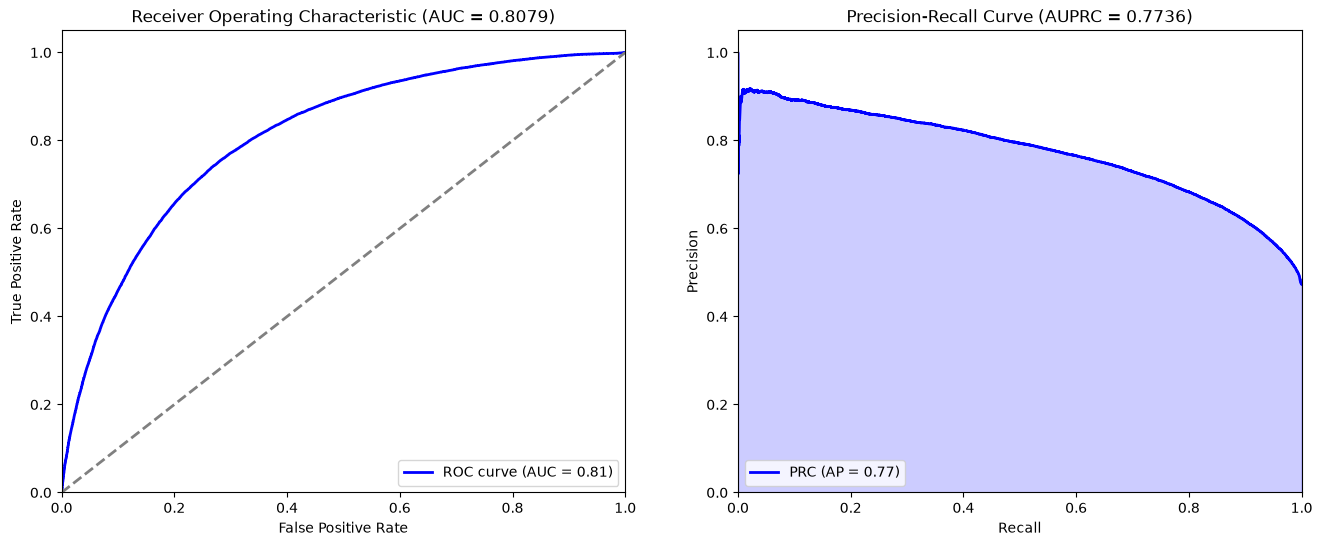

In [ ]:
plots.plot_roc_prc(test.y, lr.predict_proba(test.X)[:, 1])

## Random Forest

In [25]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)


# log with mlflow
with mlflow.start_run(run_name="random-forest"):
    mlflow.log_params(rf.get_params())

    start_time = perf_counter()
    rf.fit(train.X, train.y)
    fit_time_seconds = perf_counter() - start_time
    mlflow.log_metric("fit_time_seconds", fit_time_seconds)

    y_true = test.y
    y_pred = rf.predict(test.X)
    y_prob = rf.predict_proba(test.X)[:, 1]

    rf_metrics = metrics.BasicMetrics(
        y_true=y_true,
        y_pred=y_pred,
        y_prob=y_prob,
        cm=confusion_matrix(y_true, y_pred, labels=rf.classes_).ravel(),
    )

    mlflow.log_metrics(rf_metrics.dict)

    # mlflow saves with skops by default - skops needs trusted types to load safely
    # and Tree isn't one of its trusted types by default (ugh)
    model_uri = log_model(
        rf, artifact_path="model", flavor="sklearn",
        skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

print(f"Training Time: {fit_time_seconds:,.2f}")
pprint(rf_metrics.dict)

Training Time: 99.15
{'accuracy': 0.7431784974005233,
 'average_precision': 0.7859945010725646,
 'f1': 0.7295175836236103,
 'fn': 11234.0,
 'fp': 11440.0,
 'precision': 0.7277292524454387,
 'recall': 0.7313147257898639,
 'roc_auc': 0.8186524921822625,
 'specificity': 0.7538514502108615,
 'tn': 35036.0,
 'tp': 30577.0}


In [26]:
# register model with mlflow
rf_version = register_model_version(model_uri, model_name="random-forest", alias="basic")

Successfully registered model 'random-forest'.
Created version '1' of model 'random-forest'.


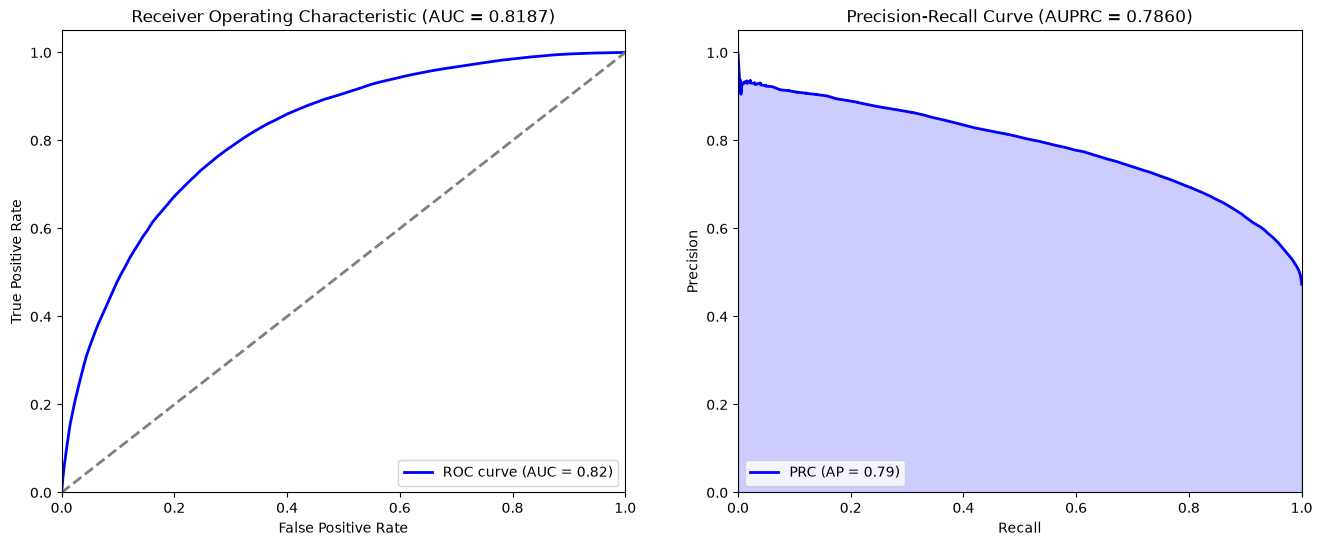

In [27]:
# plot ROC-PRC
plots.plot_roc_prc(test.y, rf.predict_proba(test.X)[:, 1])

## XGBoost